# Quantifying if we're capturing internal variability and model uncertainty

Re-estimating the reanalysis variance calculation using MC draws across subsets of runs 

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import string
import glob
import zarr
import copy
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar

import matplotlib as mpl
from matplotlib import patches as mpatches
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
import cmocean


import distributed

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_readregs import coeffs_mortality, coeffs_gdppc
from funcs_processing import calc_uncerts
from funcs_plot import plot_map,create_segcmap

dir_list = get_params()
dir_list['aux_bigmem'] = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/'

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}
subplot_lettering = string.ascii_uppercase #string.ascii_lowercase

In [2]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 46583 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/46583/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/46583/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41429,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/46583/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:41187,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/45349/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:33579,


In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':True},
               'gdppc':{'varname':'tasmeanpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                   'gdppc':'GDP per capita growth\n(Burke, Hsiang, and Miguel 2015)',
                   'payroll':'Payroll\n(Behrer et al., 2021)'}

# How many draws of runs for each number of runs
ndraws = 100

# At what gwl to test
gwl = 2

In [8]:
overwrite = True
for proc in ['gdppc','payroll']:#params_proc:

    output_fn = f'{dir_list['aux_bigmem']}obsvar_boot_estimates_{proc}.zarr'
    if overwrite or (not os.path.exists(output_fn+'/.done')):
        #---------------------------
        # Setup
        #---------------------------
        # Load impacts projections
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*{'popwght'*params_proc[proc]['popwght']}.zarr'))
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            # With a generic run counter
            ds_tmp['exprun'] = (('idv'),np.arange(0,ds_tmp.sizes['idv']))
            ds_tmp = ds_tmp.reset_index('idv')
            for v in ['model','experiment','run']:
                ds_tmp[v] = (['idv'],ds_tmp[v].astype(object).load().values)
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')
        
        
        dss = dss.chunk({'poly_idx':500,'idv':-1,'proj_base':-1,'gwl':-1})
        dss = dss.sel(gwl=gwl)
        
        # Load max gwls 
        maxgwl = dss.maxgwl.load()
        # Figure out how many BCD-ME members reach a given GWL
        gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
        gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
        #print(gwl_counter)
        
        # Unstack into model x run array for convenience
        dss = dss.unstack('idv')['d'+proc]
        # Make sure it's still chunked to allow for uncertainty calculations along
        # run dimensions
        dss = dss.chunk({'model':-1,'exprun':-1})
        
        #---------------------------
        # Load 
        #---------------------------
        
        obsvar_estimates_all = []
        tmp_fns = []
        for mod in tqdm(dss.model.values):
            
            obsvar_estimates = []
        
            # Figure out how many runs are available for a particular model
            avail_runs = maxgwl.where(maxgwl>2).sel(model=mod).dropna('exprun').exprun
                
            max_nruns = avail_runs.sizes['exprun']
            if max_nruns == 0:
                print(f'{mod} has no run(s) with max GWL>=2, skipping.')
                continue
            elif max_nruns <= 5: 
                print(f'{mod} only has {str(max_nruns)} run(s) with max GWL>=2, skipping.')
                continue
            
            for nruns in np.arange(2,max_nruns+1):
                # Bootstrap draws (currently with replacement)
                run_ids = np.random.randint(0,avail_runs.max(),size=(nruns,ndraws))
                run_ids = xr.DataArray(run_ids,
                                       dims = ['nrun','draw'])
        
                # Get variance across runs
                with warnings.catch_warnings():
                    warnings.filterwarnings('ignore')
                    obsvar_tmp = dss.sel(model=mod,exprun=run_ids).mean('proj_base').var('nrun')
                obsvar_tmp = obsvar_tmp.expand_dims({'nruns':[nruns]})
            
                obsvar_estimates.append(obsvar_tmp)
            obsvar_estimates = xr.concat(obsvar_estimates,dim='nruns').to_dataset(name='obsunc')
            # Separate out the mean of the last 5 nruns for reference
            obsvar_estimates['obsunc_last5'] = obsvar_estimates['obsunc'].isel(nruns = slice(-5,None)).mean(['nruns','draw'])
            # Store max number of runs for each model
            obsvar_estimates['max_nruns'] = max_nruns

            tmp_fn = re.sub(r'\.zarr',f'_{mod}_tmp.zarr',output_fn)
            utility_save(obsvar_estimates.drop_encoding(),tmp_fn,zarr_mode='w')
            obsvar_estimates = xr.open_zarr(tmp_fn)
            tmp_fns.append(tmp_fn)
        
            obsvar_estimates_all.append(obsvar_estimates)
        
        # Concatenate into single dataset
        obsvar_estimates_all = xr.concat(obsvar_estimates_all,dim='model',join='outer')
    
        obsvar_estimates_all.attrs = {'SOURCE':'4c_capturing_uncertainty.ipynb',
                                      'DESCRIPTION':(f'Internal variability in projections of {proc} at GWL{str(gwl)}, '+
                                                     f'calculated as the the variance across ensemble members of means across reanalyses for each model, '+
                                                     f'using {str(ndraws)} of #`nruns` bootstrap resampled (with replacement) ensemble members.')}
        # Rechunk for processing below
        obsvar_estimates_all = obsvar_estimates_all.chunk({'draw':-1,'nruns':-1,'model':1,'poly_idx':1000})
        utility_save(obsvar_estimates_all.drop_encoding(),output_fn,zarr_mode = 'w')
        for fn in tmp_fns:
            os.system('rm -rf '+fn)
    else:
        print(output_fn+' exists!')

  0%|          | 0/24 [00:00<?, ?it/s]

ACCESS-CM2 only has 1 run(s) with max GWL>=2, skipping.


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=39, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wi

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_gdppc_ACCESS-ESM1-5_tmp.zarr saved!
BCC-CSM2-MR only has 2 run(s) with max GWL>=2, skipping.
BCC-ESM1 has no run(s) with max GWL>=2, skipping.
CAMS-CSM1-0 only has 1 run(s) with max GWL>=2, skipping.


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=39, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=11, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wi

...

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_payroll_MPI-ESM1-2-LR_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=5, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=10, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_payroll_MRI-ESM2-0_tmp.zarr saved!
NESM3 only has 1 run(s) with max GWL>=2, skipping.
NorESM2-MM only has 2 run(s) with max GWL>=2, skipping.
TaiESM1 only has 1 run(s) with max GWL>=2, skipping.
/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_payroll.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=5, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_payroll.zarr saved!


In [9]:
imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}


obsvar_estimates_all = {proc:(xr.open_zarr(f'{dir_list['aux_bigmem']}obsvar_boot_estimates_{proc}.zarr').
                               sel(imp_params[proc]).
                              chunk({'poly_idx':1000}))
                        for proc in params_proc}
ratio_to_final_obsunc = {proc:obsvar_estimates_all[proc].obsunc.mean('draw') / obsvar_estimates_all[proc].obsunc_last5
                         for proc in params_proc}
ratio_to_final_obsunc = {proc:ratio_to_final_obsunc[proc].compute() for proc in ratio_to_final_obsunc}

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour o

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/capturing_uncertainty_internal.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/capturing_uncertainty_internal.png saved!


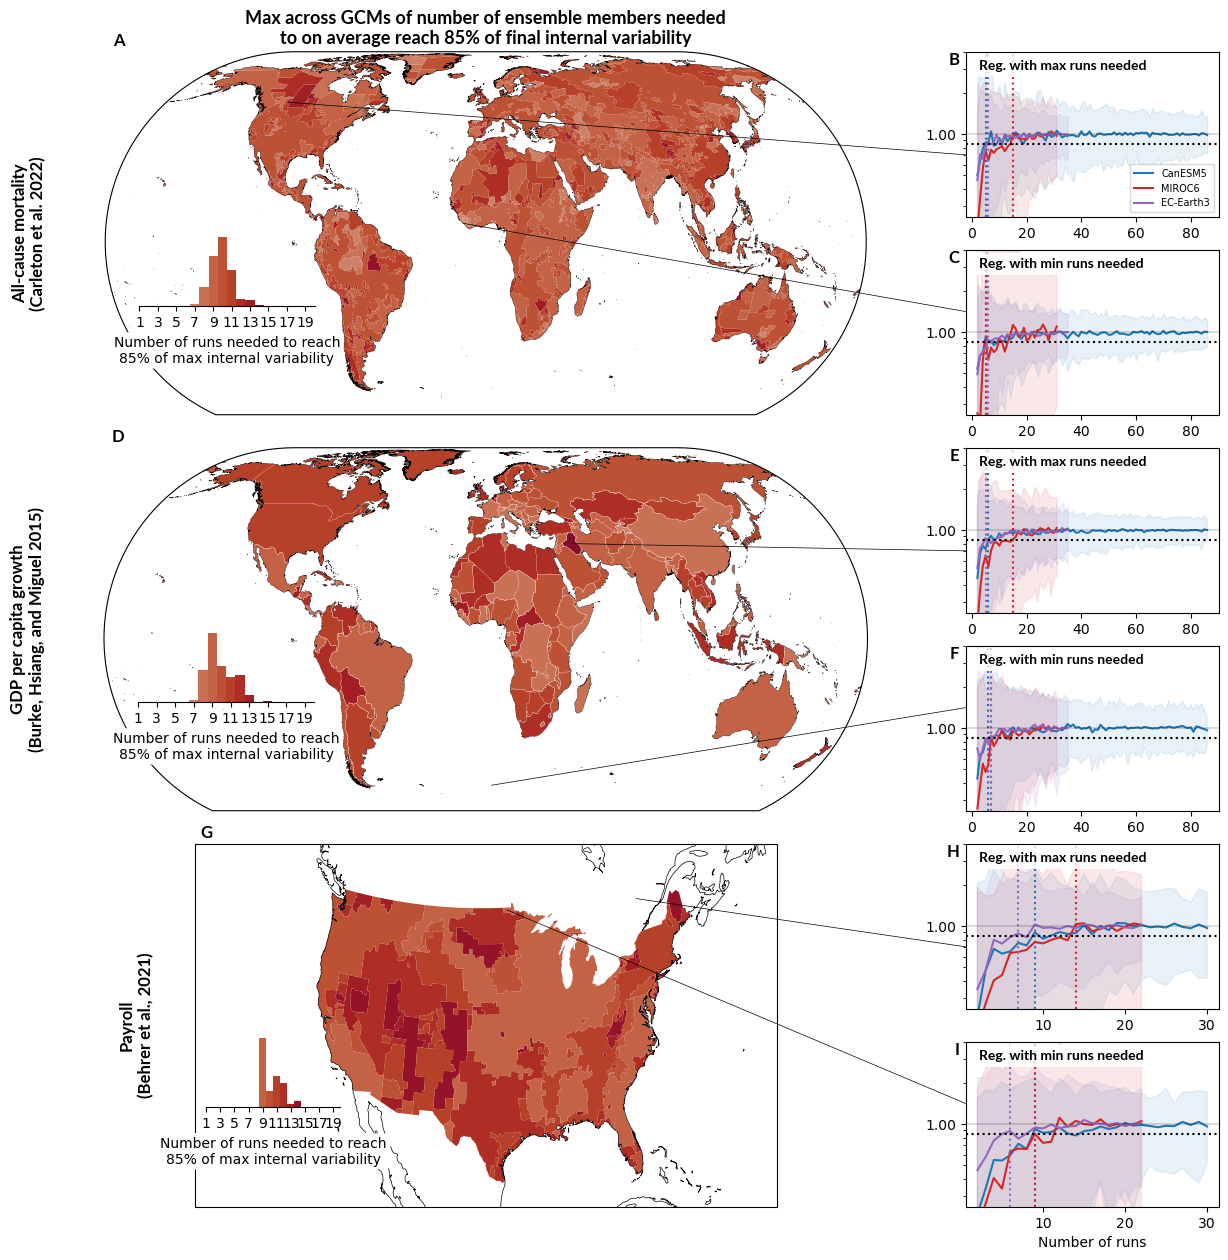

In [10]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/capturing_uncertainty_internal'

levels = 20
cbar_params = {'vmin':0,'vmax':levels-1,'levels':20,'cmap':cmocean.cm.amp}

thresh = 0.85

projs = {'dmortality':ccrs.EckertIV(),
         'dgdppc':ccrs.EckertIV(),
         'dpayroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}



fig = plt.figure(figsize=(15,5*len(params_proc)))
gs = plt.GridSpec(nrows=2*len(params_proc),ncols=4)


for row_idx,proc in enumerate(params_proc):
    
    # Load shapefile and process centroids
    gdf = load_shp(proc)
    centroids = gdf.geometry.to_crs('EPSG:4087').centroid
    centroids = centroids.to_crs('EPSG:4326')
    centroids = centroids.to_frame(name='geometry')
    centroids['locid'] = gdf.locid.values
    centroids = centroids.set_index('locid')


    # Load uncertainty estimates
    unc_fn = f'{dir_list['aux_bigmem']}obsvar_boot_estimates_{proc}.zarr'
    obsvar_estimates_all = xr.open_zarr(unc_fn).set_index({'poly_idx':'locid'})
    obsvar_estimates_all = obsvar_estimates_all.sel(imp_params[proc])

    # Calculate obsvar estimates normalized to that of last 5 nruns mean
    obsvar_estimates_all_norm = obsvar_estimates_all['obsunc'] / obsvar_estimates_all['obsunc_last5']

    # Prep for geogrpahic plotting
    ratio_to_final_obsunc_tmp = ratio_to_final_obsunc[proc].set_index({'poly_idx':'locid'})
    ratio_to_final_obsunc_tmp = ratio_to_final_obsunc_tmp.sel(poly_idx = gdf.locid.values)
    ratio_to_final_obsunc_tmp = ratio_to_final_obsunc_tmp.dropna(dim='poly_idx',how='all')
    gdf = gdf.set_index('locid').loc[ratio_to_final_obsunc_tmp.poly_idx.values,:].reset_index()
    
    #--------------------------------
    # Map ---------------------------
    #--------------------------------
    ax_map = fig.add_subplot(gs[(row_idx*2):(row_idx*2+2),0:3],projection=projs['d'+proc])
    nruns_needed = ratio_to_final_obsunc_tmp.nruns.isel(nruns = (ratio_to_final_obsunc_tmp>thresh).argmax('nruns'))
    plot_data = nruns_needed.max('model').sel(poly_idx = gdf.locid.values)

    if 'levels' in cbar_params:
        gdf['colors'],bins,colors_ref = create_segcmap(plot_data.sel(poly_idx = gdf.locid.values),
                                        cbar_params,
                                       centered = True,return_all = True)
        gdf_tmp = gdf.dissolve(by='colors').reset_index()
        
        gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax_map)
        # Plot national boundaries at least
        if proc == 'gdppc':
            gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())
            
    else:
        fig,ax_map = plot_map(plot_data.sel(poly_idx = gdf.locid.values),
             gdf,**cbar_params,fig=fig,ax=ax_map)

    if proc == 'payroll':
        ax_map.coastlines(lw=0.5)
    else:
        gpd.GeoSeries(data = gdf.union_all()).plot(facecolor='none',edgecolor='k',linewidth=0.25,ax=ax_map, 
                                              transform=ccrs.PlateCarree())
    if row_idx == 0:
        ax_map.set_title(f'Max across GCMs of number of ensemble members needed\nto on average reach {str(int(thresh*100))}% of final internal variability',
                         font=extra_fonts['lato-bold'],fontsize=13)


    # Row labels
    ax_map.annotate(proc_full_names[proc],
                (-0.1,0.5),xycoords = 'axes fraction',
                fontweight='bold',fontsize=12,va='center',ha='center',
                rotation=90,font=extra_fonts['lato-bold'])

    if proc == 'payroll':
        ax_map.set_extent((-135, -64, 23.7, 50.6),
                          crs = ccrs.PlateCarree())

    # Subplot label
    ax_map.annotate(subplot_lettering[row_idx*3],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])
    
    #----- Inset histogram
    if 'levels' in cbar_params:
        nbins = cbar_params['levels']
    else:
        nbins = 20
    if proc == 'payroll':
        ax = ax_map.inset_axes([0.065-0.045, 0.275, 0.2+0.03, 0.2], xticks=[], yticks=[])
    else:
        ax = ax_map.inset_axes([0.09-0.045, 0.3, 0.2+0.03, 0.2], xticks=[], yticks=[])
    
    N, bins, patches = (plot_data.clip(min=cbar_params['vmin'],
                                       max=cbar_params['vmax']).
                        plot.hist(bins=bins,ax=ax))
    
    for binid, patch in enumerate(patches):
        patch.set_facecolor(colors_ref[binid])
    
    for side in ['top','left','right']:
        ax.spines[side].set_visible(False)
    ax.set_xticks(np.arange(1,levels+1,2))
    ax.set_xlim(1,levels)
    ax.set_yticks([])
    ax.set_xlabel('Number of runs needed to reach\n'+f'{str(int(thresh*100))}% of max internal variability',
                  bbox={'boxstyle':'round4','edgecolor':'none','facecolor':'w'})
    ax.set_ylabel('')
    ax.set_title('')

    # Remove axis background
    ax.set_facecolor('none')
    
    #--------------------------------
    # Sample plots ------------------
    #--------------------------------
    
    reg_idxs = {'max':plot_data.poly_idx.isel(poly_idx = plot_data.argmax('poly_idx')).values,
                'min':plot_data.poly_idx.isel(poly_idx = plot_data.argmin('poly_idx')).values}
    
    for plt_idx,reg_typ in enumerate(reg_idxs):
    
        centroid = centroids.loc[reg_idxs[reg_typ],:].iloc[0]
    
        sp = {'poly_idx':reg_idxs[reg_typ]}
        
        colors = {'CanESM5':'tab:blue',
                  'MIROC6':'tab:red',
                  'EC-Earth3':'tab:purple'}
        
        ax = fig.add_subplot(gs[row_idx*2+plt_idx,3])
        
        for mod,color in colors.items():
            ratio_to_final_obsunc_tmp.sel(model=mod).sel(**sp).plot(color=color,label=mod)
            ax.fill_between(obsvar_estimates_all_norm.nruns,
                            obsvar_estimates_all_norm.sel(model=mod).sel(**sp).quantile(0.025,'draw'),
                            obsvar_estimates_all_norm.sel(model=mod).sel(**sp).quantile(0.975,'draw'),
                            color=color,alpha=0.1)
            
            ax.axvline((ratio_to_final_obsunc_tmp.nruns.isel(nruns=(ratio_to_final_obsunc_tmp.sel(model=mod,**sp)>thresh).argmax().values).values),
                   color=color,linestyle=':')
        
        
        ax.axhline(1,color='k',linestyle='-',lw=0.2)
        ax.axhline(thresh,color='k',linestyle=':')
    
        
        if (plt_idx == 0) and (row_idx == 0):
            ax.legend(fontsize=7,loc='lower right')
            ax.set_xlabel('')
        elif (plt_idx == 1) and (row_idx == len(params_proc) - 1):
            ax.set_xlabel('Number of runs')
        else:
            ax.set_xlabel('')
        ax.set_title('')
        ax.annotate('Reg. with '+reg_typ+' runs needed',(0.05,0.95),xycoords='axes fraction',va='top',
                    font=extra_fonts['lato-bold'],
                    bbox={'boxstyle':'round','fc':'w','ec':'w','alpha':0.8})
        ax.set_ylim([0.25,4])
        ax.set_yticks([0.25,0.5,0.75,thresh,1,1.5,2,4])
        ax.set_yscale('log')
        ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

        # Subplot label
        ax.annotate(subplot_lettering[row_idx*3+plt_idx+1],(-0.025,1.0),xycoords = 'axes fraction',
                                fontweight='bold',fontsize=12,va='top',ha='right',font=extra_fonts['lato-bold'])
        

        # Map point → figure coordinates
        lon_proj,lat_proj = ax_map.projection.transform_point(centroid.x, centroid.y, ccrs.PlateCarree())
        disp = ax_map.transData.transform((lon_proj, lat_proj))  # PlateCarree input
        map_fig = fig.transFigure.inverted().transform(disp)
    
        # add connection to main map
        if plt_idx == 0: 
            yloc = 0.375
        elif plt_idx == 1:
            yloc = 0.625
        con = mpl.patches.ConnectionPatch(
            #xyA=(centroid.x, centroid.y), coordsA=ax_map.transData,   # map location (lon/lat)
            xyA = map_fig, coordsA = fig.transFigure,
            xyB=(0.0, yloc), coordsB=ax.transAxes,       # left-center of subplot
            axesA=ax_map,
            axesB=ax,
            color='black',
            lw=0.5
        )
        
        fig.add_artist(con)

if save_fig:
    utility_print(output_fn)


## Model uncertainty

In [4]:
# Random draws from models

gwl =2 
# (a few minutes in total on 18 CPUs)
overwrite = False

#for proc in params_proc:
for proc in ['gdppc','payroll']:
    
    output_fn = f'{dir_list['aux_bigmem']}modvar_boot_estimates_{proc}.zarr'
    if overwrite or (not os.path.exists(output_fn+'/.done')):  
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
        #---------------------------
        # Setup --------------------
        #---------------------------
        
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
            ds_tmp = ds_tmp.reset_index('idv')
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')
        
        
        dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})
    
        # Save temporary rechunked file to make dask graphing more stable
        tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
        dss = dss.reset_index('idv')
        for v in dss.coords:
            dss[v] = dss[v].load()
        utility_save(dss.drop_encoding(),tmp_fn,zarr_mode = 'w')
        dss = xr.open_zarr(tmp_fn)
        for v in ['model','exprun','experiment','run']:
            # Explicitly cast these dims as objects because of a numpy bug
            dss[v] = dss[v].astype(object).load()
        dss = dss.set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])

        # Load into memory the subset of projections used
        dss_tmp = dss.sel(imp_params[proc]).mean('proj_base').groupby(['model']).mean().load()

    
        # Figure out the models available in total
        keep_gwl_test = 2
        nruns = dss.sel(imp_params[proc])['d'+proc].mean('poly_idx').mean('proj_base').groupby(['model']).apply(lambda x: ((~np.isnan(x)).sum('idv'))).compute()
        le_mods = nruns.sel(gwl=keep_gwl_test).where(nruns.sel(gwl=keep_gwl_test) >= 10,drop=True).model
        max_nmods = nruns.sizes['model']

        # REMOVE TaiESM
        dss_tmp = dss_tmp.sel(model = [mod for mod in dss_tmp.model.values if mod != 'TaiESM1'])
        nruns = nruns.sel(model = [mod for mod in dss_tmp.model.values if mod != 'TaiESM1'])

        #---------------------------
        # Build sample -------------
        #---------------------------
        # Get the models available for a particular GWL
        mods_tmp = nruns.sel(gwl=gwl).where(nruns.sel(gwl=gwl) > 0,drop=True).model.values
        mods_tmp = xr.Dataset(coords = {'model':(['model'],mods_tmp)})
        # Get the LE models availabe for a particular GWL that are
        mods_le_tmp = mods_tmp.sel(model=[mod for mod in mods_tmp.model.values if mod in le_mods])
        
        modvar_estimates = []
        for nmods in np.arange(2,max_nmods+1):
            # Get index draws of all models + only the LE models
            mod_ids = []
            for ms in [mods_tmp,mods_le_tmp]:
                mod_ids_tmp = np.random.randint(0,ms.sizes['model'],size=(nmods,ndraws))
                mod_ids.append(xr.DataArray(mod_ids_tmp,
                                               dims = ['nmod','draw']))
            mod_ids = xr.concat(mod_ids,dim=pd.Index(['all','les'],name='modtype'))
            
            # Build model sample from those indices 
            mod_sample = xr.concat([mods_tmp.isel(model=mod_ids.sel(modtype='all')),
                                    mods_le_tmp.isel(model=mod_ids.sel(modtype='les'))],
                                   dim=mod_ids.modtype,coords='all')
            
            # Get impact projection data from the sample
            modvar_tmp = dss_tmp.sel(gwl=gwl)['d'+proc].sel(model=mod_sample.model)
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore')
                modvar_tmp = modvar_tmp.var('nmod')
            modvar_tmp = modvar_tmp.expand_dims({'nmods':[nmods]})
            
            modvar_estimates.append(modvar_tmp)
        
        modvar_estimates = xr.concat(modvar_estimates,dim='nmods').to_dataset(name='modunc')
        # Make sure the le mods draws only go up to the number of le mods
        modvar_estimates['modunc'].loc[{'modtype':'les'}] = modvar_estimates['modunc'].loc[{'modtype':'les'}].where(modvar_estimates.nmods <= len(le_mods))
        # Separate out the mean of the last 5 nruns for reference
        modvar_estimates['modunc_last5'] = modvar_estimates['modunc'].isel(nmods = slice(-5,None)).mean(['nmods','draw'])
        # Store max number of runs for each model
        modvar_estimates['max_nruns'] = max_nmods
        

        #---------------------------
        # Export -------------------
        #---------------------------
        # Save
        modvar_estimates.attrs['SOURCE'] = '4c_capturing_uncertainty.ipynb'
        modvar_estimates.attrs['DESCRIPTION'] = (f'Model uncertainty in projections of {proc} at GWL {str(gwl)}, '+
                                                 f'calculated as the the variance across model means, '+
                                                 f'using {str(ndraws)} of #`nmods` bootstrap resampled (with replacement) GCMs. '+
                                                 f'Variances are calculated separately across all {str(max_nmods)} GCMs '+
                                                 f'and across only the {str(le_mods.sizes['model'])} LEs with more than 10 runs at GWL {str(keep_gwl_test)}.')
        utility_save(modvar_estimates,output_fn,zarr_mode='w')

        # Remove tmp file
        os.system('rm -rf '+tmp_fn)
    else:
        print(output_fn+' exists, skipped!')
                

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/modvar_boot_estimates_gdppc.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/modvar_boot_estimates_payroll.zarr exists, skipped!


In [5]:
# 1 run per model

gwl =2 
# (a few minutes in total on 18 CPUs)
overwrite = False

le_thresh = 8

#for proc in params_proc:
for proc in ['gdppc','payroll']:
    
    output_fn = f'{dir_list['aux_bigmem']}modvar_boot_estimates_{proc}_1runpermod.zarr'
    if overwrite or (not os.path.exists(output_fn+'/.done')):  
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
        #---------------------------
        # Setup --------------------
        #---------------------------
        
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
            ds_tmp = ds_tmp.reset_index('idv')
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')
        
        
        dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})
    
        # Save temporary rechunked file to make dask graphing more stable
        tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
        dss = dss.reset_index('idv')
        for v in dss.coords:
            dss[v] = dss[v].load()
        utility_save(dss.drop_encoding(),tmp_fn,zarr_mode = 'w')
        dss = xr.open_zarr(tmp_fn)
        for v in ['model','exprun','experiment','run']:
            # Explicitly cast these dims as objects because of a numpy bug
            dss[v] = dss[v].astype(object).load()
        dss = dss.set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])

        dss_tmp = dss.sel(imp_params[proc]).mean('proj_base').load()
        dss_tmp = dss_tmp['d'+proc].sel(gwl=gwl).dropna('idv',how='all')

        # **** REMOVE TaiESM1 ****
        dss_tmp = dss_tmp.isel(idv = [mod != 'TaiESM1' for mod in dss_tmp.model.values])
        nruns = dss_tmp.mean('poly_idx').groupby(['model']).apply(lambda x: ((~np.isnan(x)).sum('idv')))
        max_nmods = nruns.sizes['model']

        #---------------------------
        # Calculate variances ------
        #---------------------------

        mod_choice = {'all':nruns.where(nruns>0,drop=True).model.values,
                      'les':nruns.where(nruns>le_thresh,drop=True).model.values}
        
        modvar_estimates = []
        for nmods in tqdm(np.arange(2,max_nmods+1)):
            draws = []
            for draw in range(ndraws):
                vars_out = []
                for modtype in ['all','les']:
                    # Get set of models to choose from
                    if modtype == 'all':
                        mod_choice_tmp = mod_choice['all']
                    elif (modtype == 'les') and (nmods <= (nruns>5).sum('model')) :
                        mod_choice_tmp = mod_choice['les']
                    else:
                        continue
                    
                    # Pick random models with replacement from models with data 
                    # for a given GWL 
                    mod_sample = np.random.choice(mod_choice_tmp,size=nmods)
                    # Pick one random run for each model
                    run_idxs = xr.apply_ufunc(lambda x: np.random.randint(0,x),
                                   nruns.sel(model = mod_sample),
                                              vectorize=True)
            
                    # Get data for the random draws of models, runs
                    draws_tmp = dss_tmp.isel(idv = [dss_tmp.groupby('model').groups[str(k.model.values)][k.values] for k in run_idxs])
        
                    # Get variance across model / run draws
                    vars_out.append(draws_tmp.var('idv').expand_dims({'modtype':[modtype]}))
                
                # Get variance across model / run draws
                draws.append(xr.concat(vars_out,dim='modtype'))
            
            modvar_estimates.append(xr.concat(draws,dim='draw').expand_dims({'nmods':[nmods]}))
        
        # Concatenate into single ds
        modvar_estimates = xr.concat(modvar_estimates,dim='nmods',join='outer').to_dataset(name='modunc')
        
        # Separate out the mean of the last 5 nruns for reference
        modvar_estimates['modunc_last5'] = modvar_estimates['modunc'].isel(nmods = slice(-5,None)).mean(['nmods','draw'])
        # Store max number of runs for each model
        modvar_estimates['max_nruns'] = max_nmods
        
        #---------------------------
        # Export -------------------
        #---------------------------
        # Save
        modvar_estimates.attrs['SOURCE'] = '4c_capturing_uncertainty.ipynb'
        modvar_estimates.attrs['DESCRIPTION'] = (f'Model uncertainty in projections of {proc} at GWL {str(gwl)}, '+
                                                 f'calculated as the the variance across random draws of one run per model, '+
                                                 f'using {str(ndraws)} of #`nmods` bootstrap resampled (with replacement) GCMs. '+
                                                 f'Variances are calculated separately across all {str(max_nmods)} GCMs '+
                                                 f'and across only the {str((nruns.where(nruns>le_thresh,drop=True).sizes['model']))} LEs with more than {str(le_thresh)} runs at GWL {str(gwl)}.')
        utility_save(modvar_estimates,output_fn,zarr_mode='w')
        
        # Remove tmp file
        os.system('rm -rf '+tmp_fn)
    else:
        print(output_fn+' exists, skipped!')
        


/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/modvar_boot_estimates_gdppc_1runpermod.zarr exists, skipped!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/modvar_boot_estimates_payroll_1runpermod.zarr exists, skipped!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/capturing_uncertainty_model.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/capturing_uncertainty_model.png saved!


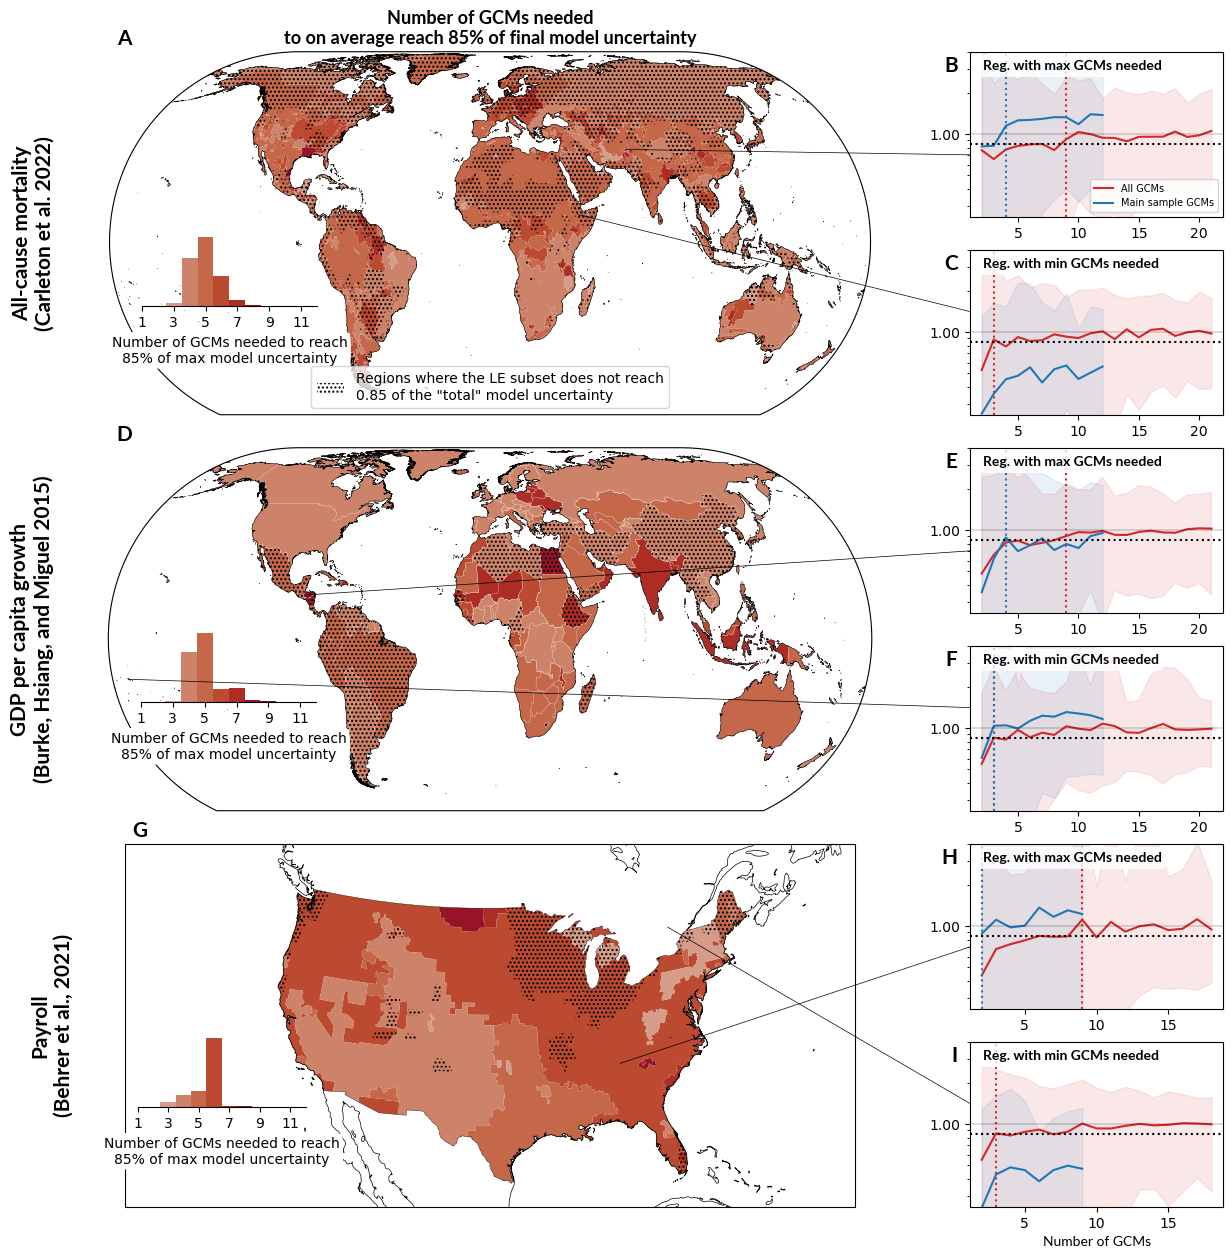

In [6]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/capturing_uncertainty_model'

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

levels = 12
cbar_params = {'vmin':0,'vmax':levels-1,'levels':levels,'cmap':cmocean.cm.amp}

thresh = 0.85

colors = {'all':'tab:red',
          'les':'tab:blue'}
names = {'all':'All GCMs',
         'les':'Main sample GCMs'}

sample_type = '_1runpermod'# or ''


fig = plt.figure(figsize=(15,5*len(params_proc)))
gs = plt.GridSpec(nrows=2*len(params_proc),ncols=4)


for row_idx,proc in enumerate(params_proc):
    # Load shapefile and process centroids
    gdf = load_shp(proc)
    centroids = gdf.geometry.to_crs('EPSG:4087').centroid
    centroids = centroids.to_crs('EPSG:4326')
    centroids = centroids.to_frame(name='geometry')
    centroids['locid'] = gdf.locid.values
    centroids = centroids.set_index('locid')
    
    modvar_estimates = xr.open_zarr(f'{dir_list['aux_bigmem']}modvar_boot_estimates_{proc}{sample_type}.zarr').load()
    modvar_estimates = modvar_estimates.set_index({'poly_idx':'locid'})

    # Calculate obsvar estimates normalized to that of last 5 nruns mean
    # Normalize both the LE and full model draws to the full model variance
    ratio_to_final_modunc = modvar_estimates.modunc.mean('draw') / modvar_estimates.modunc_last5.sel(modtype='all')
    modvar_estimates_norm = modvar_estimates['modunc'] / modvar_estimates['modunc_last5'].sel(modtype='all')
    
    # Prep for geogrpahic plotting
    ratio_to_final_modunc = ratio_to_final_modunc.sel(poly_idx = gdf.locid.values)
    ratio_to_final_modunc = ratio_to_final_modunc.dropna(dim='poly_idx',how='all')
    gdf = gdf.set_index('locid').loc[ratio_to_final_modunc.poly_idx.values,:].reset_index()

    #--------------------------------
    # Map ---------------------------
    #--------------------------------
    ax_map = fig.add_subplot(gs[(row_idx*2):(row_idx*2+2),0:3],projection=projs[proc])
    nmods_needed = ratio_to_final_modunc.nmods.isel(nmods = (ratio_to_final_modunc>thresh).argmax('nmods'))
    plot_data = nmods_needed.sel(poly_idx = gdf.locid.values,modtype='all')

    if 'levels' in cbar_params:
        gdf['colors'],bins,colors_ref = create_segcmap(plot_data.sel(poly_idx = gdf.locid.values),
                                        cbar_params,
                                       centered = True,return_all = True)
        gdf_tmp = gdf.dissolve(by='colors').reset_index()
        
        gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax_map)
        # Plot national boundaries at least
        if proc == 'gdppc':
            gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())
            
    else:
        fig,ax_map = plot_map(plot_data.sel(poly_idx = gdf.locid.values),
             gdf,**cbar_params,fig=fig,ax=ax_map)

    if proc == 'payroll':
        ax_map.coastlines(lw=0.5)
    else:
        gpd.GeoSeries(data = gdf.union_all()).plot(facecolor='none',edgecolor='k',linewidth=0.25,ax=ax_map, 
                                              transform=ccrs.PlateCarree())
    # Plot outline of areas where the LE model subset we use 
    # spans at least `thresh` of the "total" model uncert
    gdf['les_hit_thresh'] = (ratio_to_final_modunc.sel(modtype='les',poly_idx=gdf.locid.values).max('nmods')>thresh).values
    #(gdf.where(gdf['les_hit_thresh']).dropna().dissolve().plot(facecolor='none',edgecolor='greenyellow',ax=ax_map))
    (gdf.where(~gdf['les_hit_thresh']).dropna().dissolve().
     plot(facecolor='none',linewidth=0,hatch='....',ax=ax_map,
          transform=ccrs.PlateCarree()))
    # Plot coastlines
    gpd.GeoSeries(data = gdf.union_all()).plot(facecolor='none',edgecolor='k',linewidth=0.25,ax=ax_map,
                                               transform=ccrs.PlateCarree())

    if row_idx == 0:
        ax_map.set_title(f'Number of GCMs needed\nto on average reach {str(int(thresh*100))}% of final model uncertainty',
                         font=extra_fonts['lato-bold'],fontsize=13)
    
    # Row labels
    ax_map.annotate(proc_full_names[proc],
                (-0.1,0.5),xycoords = 'axes fraction',
                fontweight='bold',fontsize=15,va='center',ha='center',
                rotation=90,font=extra_fonts['lato-bold'])

    if proc == 'payroll':
        ax_map.set_extent((-135, -64, 23.7, 50.6),
                          crs = ccrs.PlateCarree())

    # Subplot label
    ax_map.annotate(subplot_lettering[row_idx*3],(0.01,1.01),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=15,va='bottom',font=extra_fonts['lato-bold'])

    #----- Hatching legend
    if row_idx == 0:
        ax_map.legend(handles=[mpatches.Patch(facecolor='none',
                                          linewidth=0,
                                           hatch='....',
                                          label = 'Regions where the LE subset does not reach\n'+f'{thresh} of the "total" model uncertainty')],
                  loc = 'lower center')
    
    #----- Inset histogram
    if 'levels' in cbar_params:
        nbins = cbar_params['levels']
    else:
        nbins = 20
    if proc == 'payroll':
        ax = ax_map.inset_axes([0.065-0.0475, 0.275, 0.2+0.03, 0.2], xticks=[], yticks=[])
    else:
        ax = ax_map.inset_axes([0.09-0.0475, 0.3, 0.2+0.03, 0.2], xticks=[], yticks=[])
    
    N, bins, patches = (plot_data.clip(min=cbar_params['vmin'],
                                       max=cbar_params['vmax']).
                        plot.hist(bins=bins,ax=ax))
    
    for binid, patch in enumerate(patches):
        patch.set_facecolor(colors_ref[binid])
    
    for side in ['top','left','right']:
        ax.spines[side].set_visible(False)
    ax.set_xticks(np.arange(1,levels+1,2))
    ax.set_xlim(1,levels)
    ax.set_yticks([])
    ax.set_xlabel('Number of GCMs needed to reach\n'+f'{str(int(thresh*100))}% of max model uncertainty',
                  bbox={'boxstyle':'round4','edgecolor':'none','facecolor':'w'})
    ax.set_ylabel('')
    ax.set_title('')

    # Remove axis background
    ax.set_facecolor('none')

    #--------------------------------
    # Sample plots ------------------
    #--------------------------------
    
    reg_idxs = {'max':plot_data.poly_idx.isel(poly_idx = plot_data.argmax('poly_idx')).values,
                'min':plot_data.poly_idx.isel(poly_idx = plot_data.argmin('poly_idx')).values}
    
    for plt_idx,reg_typ in enumerate(reg_idxs):
    
        centroid = centroids.loc[reg_idxs[reg_typ],:].iloc[0]
    
        sp = {'poly_idx':reg_idxs[reg_typ]}
        
        ax = fig.add_subplot(gs[row_idx*2+plt_idx,3])
        
        for modtype,color in colors.items():
            ratio_to_final_modunc.sel(**sp,modtype=modtype).plot(color=color,label=names[modtype])
            ax.fill_between(modvar_estimates_norm.nmods,
                            modvar_estimates_norm.sel(**sp,modtype=modtype).quantile(0.025,'draw'),
                            modvar_estimates_norm.sel(**sp,modtype=modtype).quantile(0.975,'draw'),
                            color=color,alpha=0.1)

            if np.any(ratio_to_final_modunc.sel(modtype=modtype,**sp)>thresh):
                ax.axvline((ratio_to_final_modunc.nmods.isel(nmods=(ratio_to_final_modunc.sel(modtype=modtype,**sp)>thresh).argmax().values).values),
                       color=color,linestyle=':')
        
        
        ax.axhline(1,color='k',linestyle='-',lw=0.2)
        ax.axhline(thresh,color='k',linestyle=':')
    
        
        if (plt_idx == 0) and (row_idx == 0):
            ax.legend(fontsize=7,loc='lower right')
            ax.set_xlabel('')
        elif (plt_idx == 1) and (row_idx == len(params_proc) - 1):
            ax.set_xlabel('Number of GCMs',font=extra_fonts['lato'])
        else:
            ax.set_xlabel('')
        ax.set_title('')
        ax.annotate('Reg. with '+reg_typ+' GCMs needed',(0.05,0.95),xycoords='axes fraction',va='top',
                    font=extra_fonts['lato-bold'],
                    bbox={'boxstyle':'round','fc':'w','ec':'w','alpha':0.8})
        ax.set_ylim([0.25,4])
        ax.set_yticks([0.25,0.5,0.75,thresh,1,1.5,2,4])
        ax.set_yscale('log')
        ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

        # Subplot label
        ax.annotate(subplot_lettering[row_idx*3+plt_idx+1],(-0.05,0.975),xycoords = 'axes fraction',
                                fontweight='bold',fontsize=15,va='top',ha='right',font=extra_fonts['lato-bold'])
        
    
        # Map point → figure coordinates
        lon_proj,lat_proj = ax_map.projection.transform_point(centroid.x, centroid.y, ccrs.PlateCarree())
        disp = ax_map.transData.transform((lon_proj, lat_proj))  # PlateCarree input
        map_fig = fig.transFigure.inverted().transform(disp)
    
        # add connection to main map
        if plt_idx == 0: 
            yloc = 0.375
        elif plt_idx == 1:
            yloc = 0.625
        con = mpl.patches.ConnectionPatch(
            #xyA=(centroid.x, centroid.y), coordsA=ax_map.transData,   # map location (lon/lat)
            xyA = map_fig, coordsA = fig.transFigure,
            xyB=(0.0, yloc), coordsB=ax.transAxes,       # left-center of subplot
            axesA=ax_map,
            axesB=ax,
            color='black',
            lw=0.5
        )
        
        fig.add_artist(con)

if save_fig:
    utility_print(output_fn)

In [25]:
ax_map.projection.transform_point(centroid.x, centroid.y, ccrs.PlateCarree())

(np.float64(2194838.8593880855), np.float64(1416140.0393108001))

In [26]:
ax_map.projection

<Projected CRS: +proj=aea +ellps=WGS84 +lon_0=-100 +lat_0=35 +x_0= ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Albers Equal Area
Datum: Unknown based on WGS 84 ellipsoid
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich